<a href="https://colab.research.google.com/github/FattahulAlim/GlucoSafe/blob/Fattah/ml-model/Pengujian_Model_PBL_GlucoSafe.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import Library
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

df_raw = pd.read_csv('/content/drive/MyDrive/pbl-ml/diabetes_binary_5050split_health_indicators_BRFSS2015.csv')
LABEL = 'Diabetes_binary'   # label sudah 0 dan 1
print("Ukuran data:", df_raw.shape)
df_raw.head()

Mounted at /content/drive
Ukuran data: (70692, 22)


,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0


In [ ]:
# Cek data awal
print("Tipe data tiap kolom:")
print(df_raw.dtypes.value_counts())

print("\nTotal missing value per kolom (hanya yang > 0):")
missing = df_raw.isnull().sum()
print(missing[missing > 0] if missing.sum() > 0 else "Tidak ada missing value")

print(f"\nJumlah baris duplikat: {df_raw.duplicated().sum()}")

print("\nSebaran kelas Diabetes_binary (0=tidak, 1=diabetes):")
print(df_raw[LABEL].value_counts().sort_index())

Tipe data tiap kolom:
float64    22
Name: count, dtype: int64

Total missing value per kolom (hanya yang > 0):
Tidak ada missing value

Jumlah baris duplikat: 1635

Sebaran kelas Diabetes_binary (0=tidak, 1=diabetes):
Diabetes_binary
0.0    35346
1.0    35346
Name: count, dtype: int64


In [ ]:
# Preprocessing
FITUR_DIBUANG = ['Income', 'CholCheck', 'HvyAlcoholConsump',
                 'AnyHealthcare', 'NoDocbcCost', 'Education']

df = df_raw.copy()
print(f"Data awal: {len(df)} baris x {df.shape[1]} kolom")
print(f"Sebaran kelas awal: {df[LABEL].value_counts().sort_index().to_dict()}")

# 1. Buang fitur
df = df.drop(columns=FITUR_DIBUANG)
print(f"Setelah buang fitur    : {df.shape[1]} kolom (termasuk label)")

# 2. Hapus duplikat (sebelum split)
n_sebelum = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Setelah hapus duplikat : {len(df)} baris (terbuang {n_sebelum - len(df)})")
print(f"Sebaran kelas akhir    : {df[LABEL].value_counts().sort_index().to_dict()}")

# 3. Tipe data (semua int kecuali BMI), label jadi int
df = df.astype({c: "int64" for c in df.columns if c != "BMI"})
df["BMI"] = df["BMI"].astype(float)

# 4. Pisah fitur dan label
X = df.drop(columns=[LABEL])
y = df[LABEL]
print(f"Jumlah fitur: {X.shape[1]} -> {list(X.columns)}")

Data awal: 70692 baris x 22 kolom
Sebaran kelas awal: {0.0: 35346, 1.0: 35346}
Setelah buang fitur    : 16 kolom (termasuk label)
Setelah hapus duplikat : 63197 baris (terbuang 7495)
Sebaran kelas akhir    : {0.0: 29885, 1.0: 33312}
Jumlah fitur: 15 -> ['HighBP', 'HighChol', 'BMI', 'Smoker', 'Stroke', 'HeartDiseaseorAttack', 'PhysActivity', 'Fruits', 'Veggies', 'GenHlth', 'MentHlth', 'PhysHlth', 'DiffWalk', 'Sex', 'Age']


In [ ]:
# 5. Split (stratify supaya proporsi kelas terjaga)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Kelas train:", y_train.value_counts().sort_index().to_dict())
print("Kelas test :", y_test.value_counts().sort_index().to_dict())

Train: (50557, 15) | Test: (12640, 15)
Kelas train: {0: 23908, 1: 26649}
Kelas test : {0: 5977, 1: 6663}


In [ ]:
# 6. Outlier BMI: clip pakai batas IQR dari train saja
q1, q3 = X_train["BMI"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
X_train["BMI"] = X_train["BMI"].clip(low, high)
X_test["BMI"] = X_test["BMI"].clip(low, high)

In [ ]:
# 7. Scaling kolom numerik/ordinal (fit hanya di train)
num_cols = ["BMI", "Age", "GenHlth", "MentHlth", "PhysHlth"]

scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()
X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Mean/std train (scaled):")
print(X_train_scaled[num_cols].agg(["mean", "std"]).round(3))

Mean/std train (scaled):
      BMI  Age  GenHlth  MentHlth  PhysHlth
mean  0.0 -0.0      0.0       0.0       0.0
std   1.0  1.0      1.0       1.0       1.0


# Model ANN

In [ ]:
# Import Library untuk ANN
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.metrics import (classification_report, confusion_matrix,
                             accuracy_score, roc_auc_score, roc_curve)
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Biar hasil bisa diulang
tf.random.set_seed(42)
np.random.seed(42)

In [ ]:
# 1. Siapkan data (ubah ke array float32)
X_tr = X_train_scaled.values.astype("float32")
X_te = X_test_scaled.values.astype("float32")
y_tr = y_train.values.astype("float32")
y_te = y_test.values.astype("float32")

print("Bentuk input:", X_tr.shape)

Bentuk input: (50557, 15)


In [ ]:
# 2. Bangun model ANN
model = keras.Sequential([
    layers.Input(shape=(X_tr.shape[1],)),

    layers.Dense(64, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(32, activation="relu"),
    layers.BatchNormalization(),
    layers.Dropout(0.3),

    layers.Dense(16, activation="relu"),

    layers.Dense(1, activation="sigmoid")   # output biner: 0 / 1
])

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="binary_crossentropy",
    metrics=["accuracy", keras.metrics.AUC(name="auc")]
)

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         1,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,033 (15.75 KB)

 Trainable params: 3,841 (15.00 KB)

 Non-trainable params: 192 (768.00 B)

In [ ]:
import time

callbacks = [
    EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4, min_lr=1e-5)
]

start = time.time()
history = model.fit(
    X_tr, y_tr,
    validation_split=0.2,
    epochs=100,
    batch_size=256,
    callbacks=callbacks,
    verbose=1
)
waktu_training = time.time() - start
print(f"\nWaktu training: {waktu_training:.2f} detik")

Epoch 1/100
158/158 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.6788 - auc: 0.7308 - loss: 0.6208 - val_accuracy: 0.7277 - val_auc: 0.7969 - val_loss: 0.5634 - learning_rate: 0.0010
Epoch 2/100
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7201 - auc: 0.7808 - loss: 0.5612 - val_accuracy: 0.7331 - val_auc: 0.8035 - val_loss: 0.5384 - learning_rate: 0.0010
Epoch 3/100
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7226 - auc: 0.7892 - loss: 0.5516 - val_accuracy: 0.7326 - val_auc: 0.8060 - val_loss: 0.5331 - learning_rate: 0.0010
Epoch 4/100
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7276 - auc: 0.7955 - loss: 0.5445 - val_accuracy: 0.7336 - val_auc: 0.8068 - val_loss: 0.5312 - learning_rate: 0.0010
Epoch 5/100
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7271 - auc: 0.7964 - loss: 0.5440 - val_accuracy: 0.7324 - val_auc: 0.8071 - val_loss: 0.5314 - learning_rate: 0.0010
Epoch 6/100
158/158 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.7295 - 

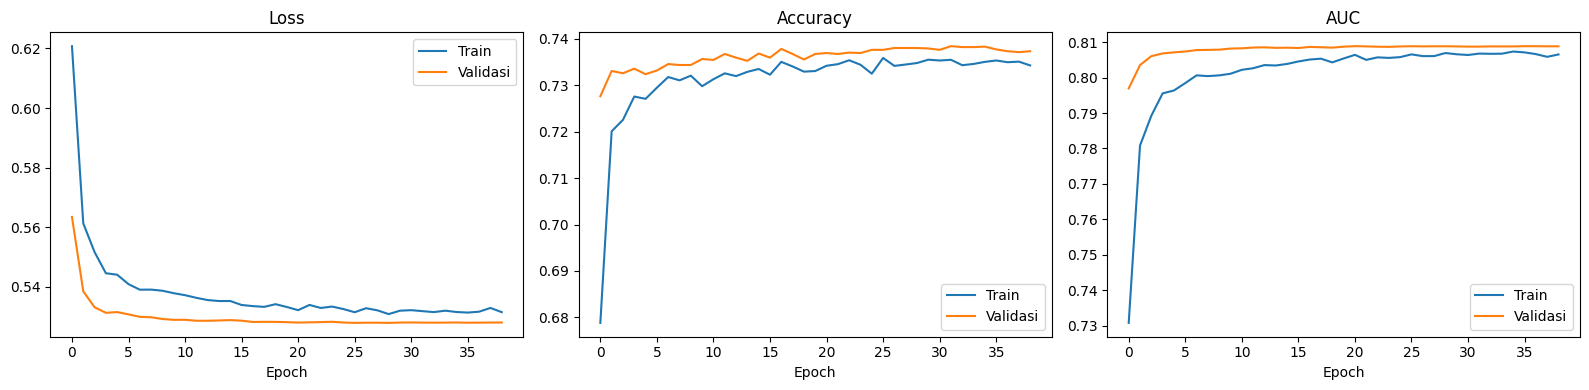

In [ ]:
# 4. Kurva training
fig, ax = plt.subplots(1, 3, figsize=(16, 4))

ax[0].plot(history.history["loss"], label="Train")
ax[0].plot(history.history["val_loss"], label="Validasi")
ax[0].set_title("Loss"); ax[0].set_xlabel("Epoch"); ax[0].legend()

ax[1].plot(history.history["accuracy"], label="Train")
ax[1].plot(history.history["val_accuracy"], label="Validasi")
ax[1].set_title("Accuracy"); ax[1].set_xlabel("Epoch"); ax[1].legend()

ax[2].plot(history.history["auc"], label="Train")
ax[2].plot(history.history["val_auc"], label="Validasi")
ax[2].set_title("AUC"); ax[2].set_xlabel("Epoch"); ax[2].legend()

plt.tight_layout()
plt.show()

395/395 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Accuracy : 0.7358
ROC-AUC  : 0.8091

Classification Report:
                precision    recall  f1-score   support

Tidak Diabetes       0.74      0.68      0.71      5977
      Diabetes       0.73      0.79      0.76      6663

      accuracy                           0.74     12640
     macro avg       0.74      0.73      0.73     12640
  weighted avg       0.74      0.74      0.73     12640



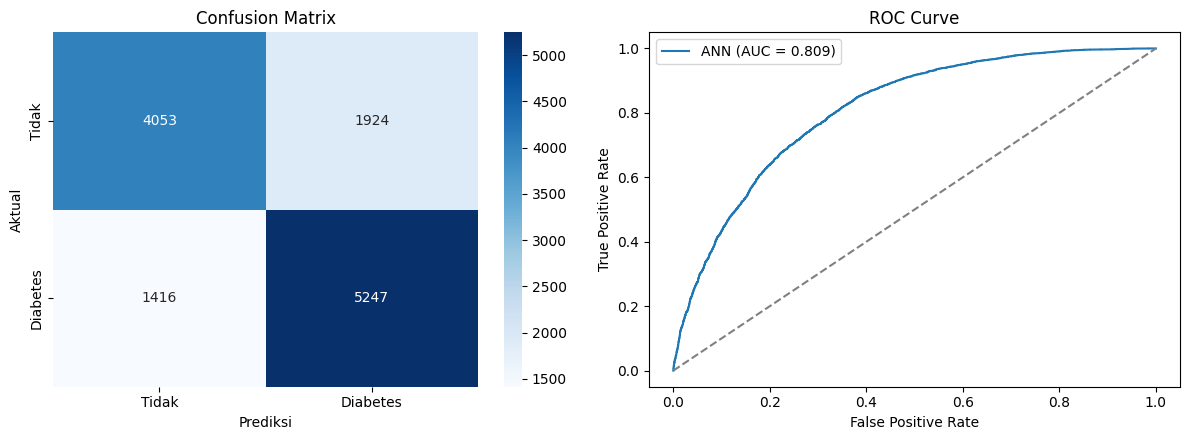

In [ ]:
# 5. Evaluasi di data test
y_prob = model.predict(X_te).ravel()
y_pred = (y_prob >= 0.5).astype(int)

print("Accuracy :", round(accuracy_score(y_te, y_pred), 4))
print("ROC-AUC  :", round(roc_auc_score(y_te, y_prob), 4))
print("\nClassification Report:")
print(classification_report(y_te, y_pred, target_names=["Tidak Diabetes", "Diabetes"]))

# Confusion matrix + ROC
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_te, y_pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=ax[0],
            xticklabels=["Tidak", "Diabetes"], yticklabels=["Tidak", "Diabetes"])
ax[0].set_title("Confusion Matrix")
ax[0].set_xlabel("Prediksi"); ax[0].set_ylabel("Aktual")

fpr, tpr, _ = roc_curve(y_te, y_prob)
ax[1].plot(fpr, tpr, label=f"ANN (AUC = {roc_auc_score(y_te, y_prob):.3f})")
ax[1].plot([0, 1], [0, 1], "--", color="gray")
ax[1].set_title("ROC Curve")
ax[1].set_xlabel("False Positive Rate"); ax[1].set_ylabel("True Positive Rate")
ax[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

y_prob = model.predict(X_te).ravel()
y_pred = (y_prob >= 0.5).astype(int)

hasil = pd.DataFrame([{
    "Model": "ANN",
    "Accuracy": accuracy_score(y_te, y_pred),
    "Precision": precision_score(y_te, y_pred),
    "Recall": recall_score(y_te, y_pred),
    "F1-Score": f1_score(y_te, y_pred),
    "ROC-AUC": roc_auc_score(y_te, y_prob),
    "Waktu training (detik)": waktu_training
}])

hasil = hasil.round(4)
hasil

395/395 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC,Waktu training (detik)
0,ANN,0.7358,0.7317,0.7875,0.7586,0.8091,37.884


# Model Random Forest

# Model Naive Bayes


# Model SVM

Hasil evaluasi SVM pada data test:
    Model  Accuracy  Precision  Recall  F1-Score  ROC-AUC  Waktu training (detik)
SVM (RBF)    0.7385     0.7257  0.8103    0.7657   0.7976                 83.1939

Classification report:
                precision    recall  f1-score   support

Tidak diabetes     0.7569    0.6585    0.7043      5977
      Diabetes     0.7257    0.8103    0.7657      6663

      accuracy                         0.7385     12640
     macro avg     0.7413    0.7344    0.7350     12640
  weighted avg     0.7404    0.7385    0.7366     12640

TN: 3936 | FP: 2041 | FN: 1264 | TP: 5399
Recall mengukur proporsi kelas diabetes yang berhasil dikenali.
FN adalah data berlabel diabetes yang diprediksi tidak diabetes.


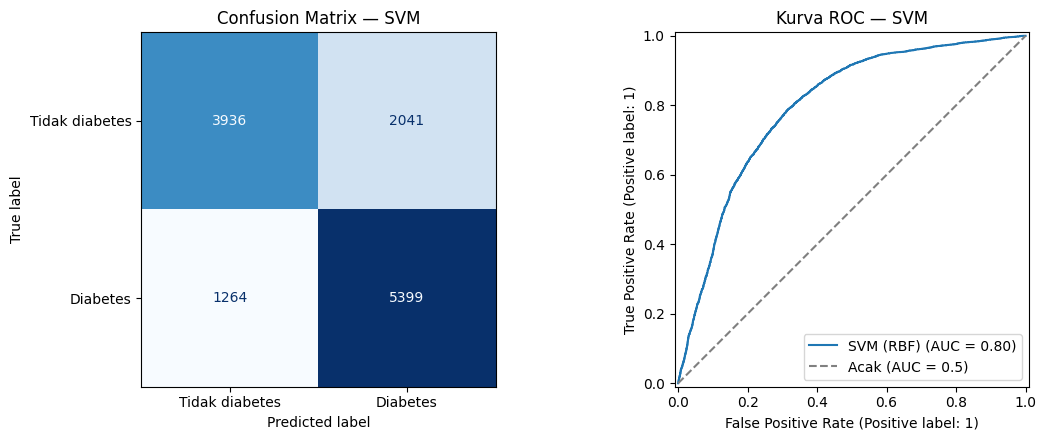

In [ ]:
# Model SVM (Support Vector Machine)
# Jalankan seluruh sel preprocessing terlebih dahulu.
import time
import matplotlib.pyplot as plt
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_auc_score, RocCurveDisplay
)

# Data sudah di-scaling menggunakan scaler yang di-fit pada data train.
# Parameter baseline ditentukan tanpa menggunakan data test.
svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", cache_size=512)

start_svm = time.perf_counter()
svm_model.fit(X_train_scaled, y_train)
svm_training_time = time.perf_counter() - start_svm

# Prediksi kelas dan skor keputusan untuk evaluasi ROC-AUC.
# Skor keputusan bukan probabilitas; probability=True tidak diperlukan.
y_pred_svm = svm_model.predict(X_test_scaled)
y_score_svm = svm_model.decision_function(X_test_scaled)

svm_results = pd.DataFrame([{
    "Model": "SVM (RBF)",
    "Accuracy": accuracy_score(y_test, y_pred_svm),
    "Precision": precision_score(y_test, y_pred_svm, zero_division=0),
    "Recall": recall_score(y_test, y_pred_svm, zero_division=0),
    "F1-Score": f1_score(y_test, y_pred_svm, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_score_svm),
    "Waktu training (detik)": svm_training_time
}])
print("Hasil evaluasi SVM pada data test:")
print(svm_results.round(4).to_string(index=False))
print("\nClassification report:")
print(classification_report(
    y_test, y_pred_svm, labels=[0, 1],
    target_names=["Tidak diabetes", "Diabetes"],
    digits=4, zero_division=0
))

cm_svm = confusion_matrix(y_test, y_pred_svm, labels=[0, 1])
tn_svm, fp_svm, fn_svm, tp_svm = cm_svm.ravel()
print(f"TN: {tn_svm} | FP: {fp_svm} | FN: {fn_svm} | TP: {tp_svm}")
print("Recall mengukur proporsi kelas diabetes yang berhasil dikenali.")
print("FN adalah data berlabel diabetes yang diprediksi tidak diabetes.")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay(
    confusion_matrix=cm_svm,
    display_labels=["Tidak diabetes", "Diabetes"]
).plot(ax=axes[0], cmap="Blues", values_format="d", colorbar=False)
axes[0].set_title("Confusion Matrix — SVM")
RocCurveDisplay.from_predictions(
    y_test, y_score_svm, name="SVM (RBF)", ax=axes[1]
)
axes[1].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acak (AUC = 0.5)")
axes[1].set_title("Kurva ROC — SVM")
axes[1].legend(loc="lower right")
plt.tight_layout()
plt.show()


# KNN